*BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Spring 2027)*  
*Updated by Arvid Lundervold — runs locally with `uv` (`bmed365-2027` kernel) or in Google Colab (originally from BMED360, 2019)*

> **Kiwi Challenge Notebook Trilogy (`Lab4-Comp-Imag/Kiwi-challenge`):**
> 1. `01-kiwi-explore.ipynb` — 3D NIfTI/DICOM headers, voxel geometry & coordinate systems
> 2. **`02-kiwi-seeds-explore.ipynb` (this notebook)** — 2D single-slice filtering, thresholding, unsupervised K-means & the Dagstuhl/CUHK 3D variational milestone
> 3. `03-kiwi-paradigms-and-verification.ipynb` — Full 3D segmentation ladder, quantitative "lesion load", & the **4-Panel Semi-Verifiability Dashboard**

# Kiwi Seed Segmentation from 7 T MRI — 2D Exploration, Clustering & Historical Context

### Import libraries & set up local / Colab file helper

In [1]:
%matplotlib inline
# Display figures inline in Jupyter / Google Colab

import os
import pathlib
import tempfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import skimage
from PIL import Image as PilImage
from IPython.display import Image, display

try:
    import nibabel as nib
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "nibabel"])
    import nibabel as nib

GITHUB_RAW_BASE = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge"

def resolve_kiwi_file(rel_path: str) -> pathlib.Path:
    """Locate an asset or data file locally, or download it automatically in Google Colab."""
    candidates = [
        pathlib.Path("..") / rel_path,
        pathlib.Path("Lab4-Comp-Imag/Kiwi-challenge") / rel_path,
        pathlib.Path(rel_path),
    ]
    for p in candidates:
        if p.exists():
            return p
    dst = pathlib.Path(rel_path)
    dst.parent.mkdir(parents=True, exist_ok=True)
    url = f"{GITHUB_RAW_BASE}/{rel_path}"
    print(f"Downloading {rel_path} from GitHub for Colab session...")
    urllib.request.urlretrieve(url, dst)
    return dst

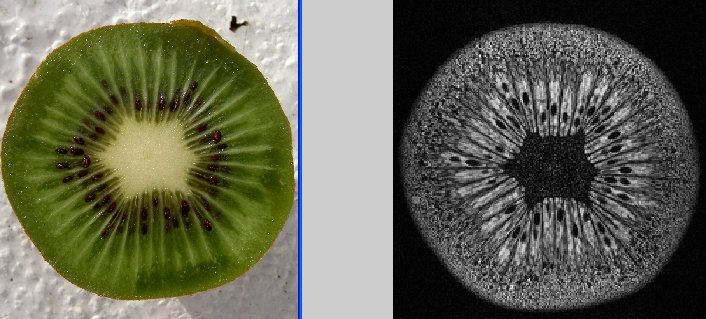

In [2]:
Image(filename=str(resolve_kiwi_file("assets/kiwi_photo_mri_20050219.jpg")), width=600)

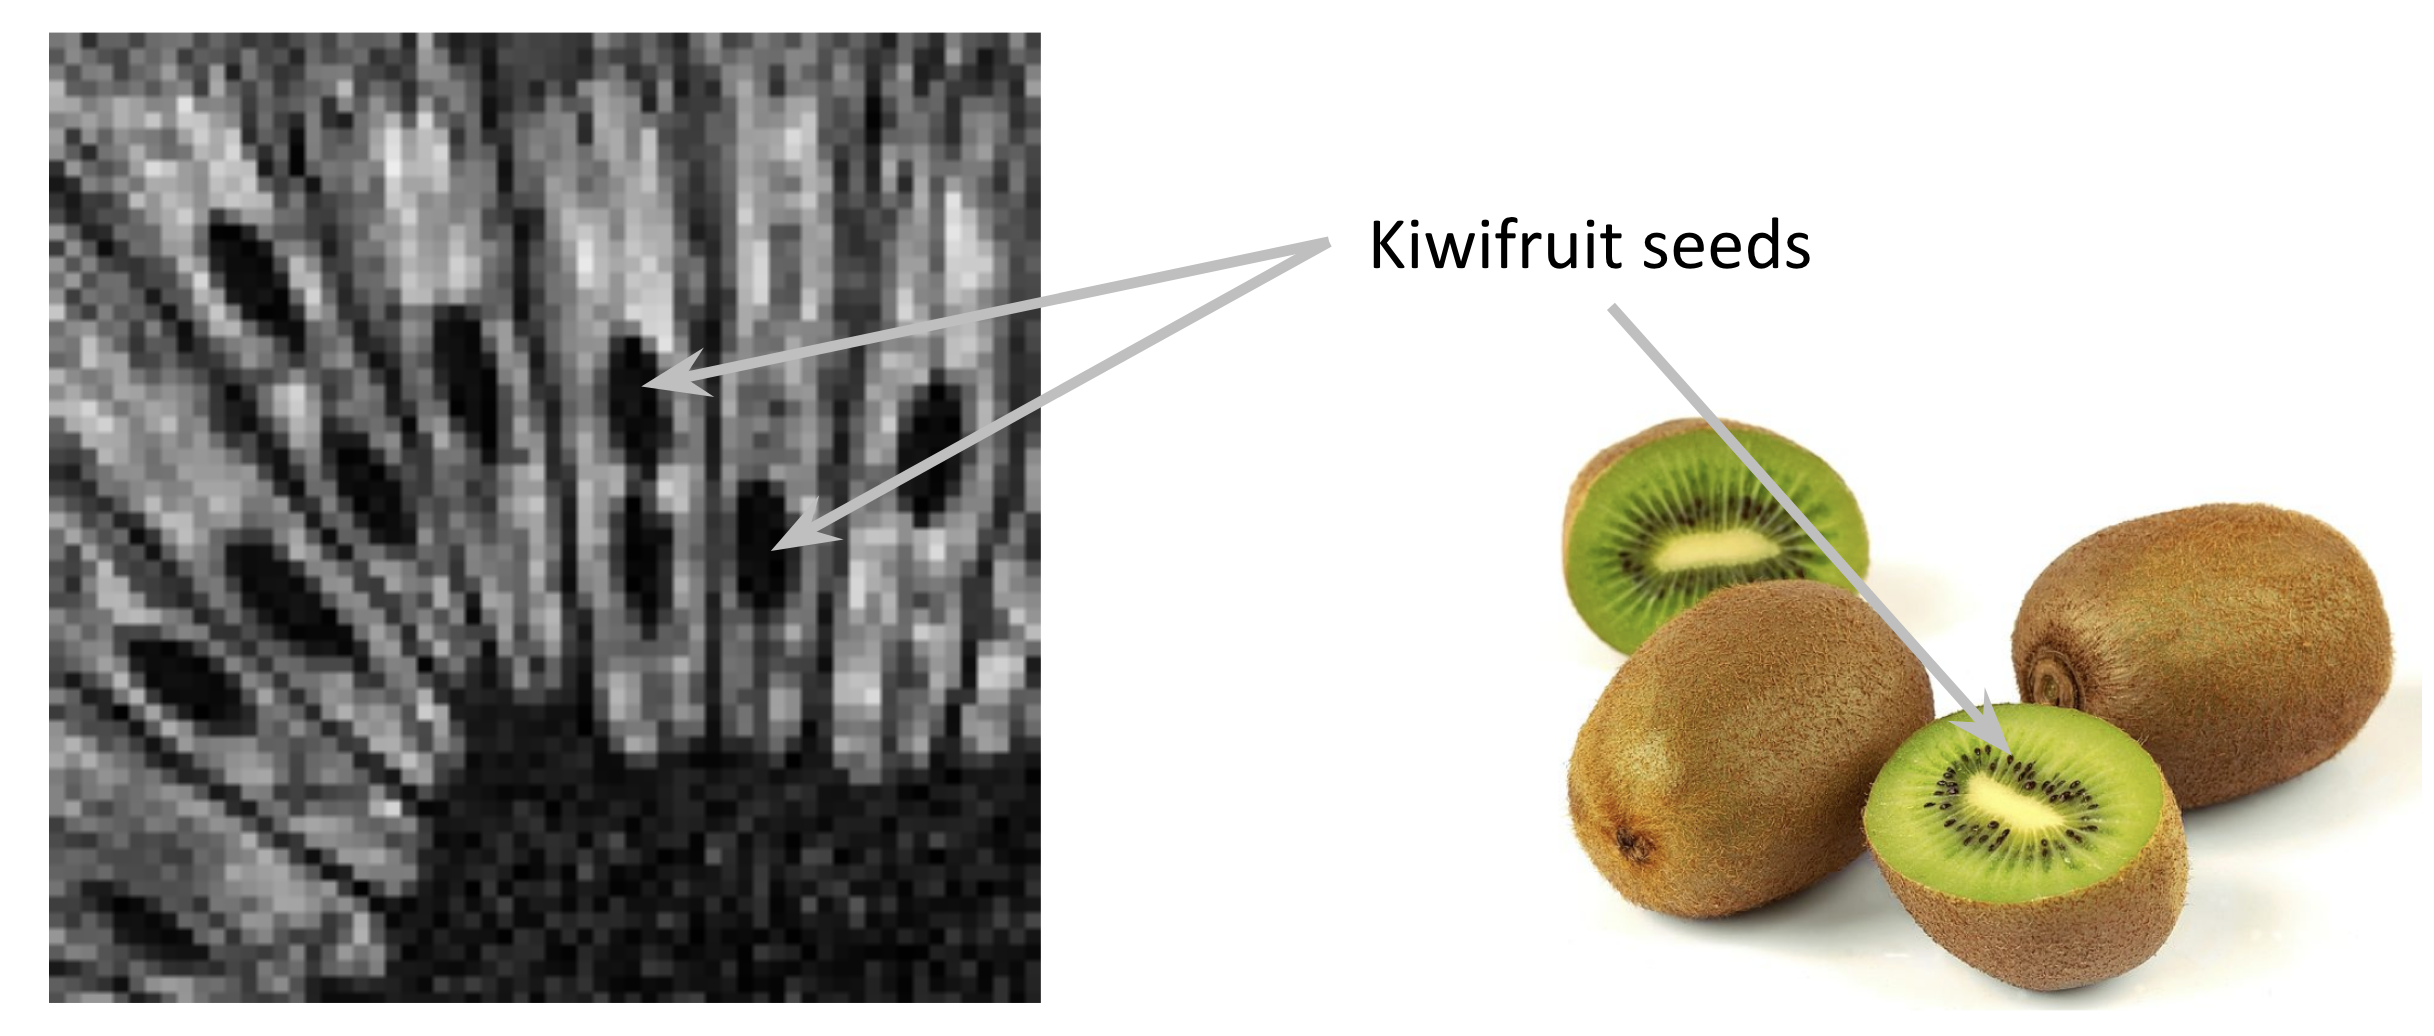

In [3]:
Image(filename=str(resolve_kiwi_file("assets/kiwi-seed-segmentation-task.png")), width=600)

## Segmentation Task

### DATA
The 3D dataset, consisting of 128 transaxial slices through the long axis of
the kiwifruit, was acquired with the 7 T [Bruker Pharmascan](https://www.bruker.com/en/products-and-solutions/preclinical-imaging/mri/pharmascan-new.html) MRI scanner at the
MIC / Vivarium, University of Bergen, using the 2D [RARE pulse sequence](https://mriquestions.com/what-is-fsetse.html)
(`Echo Train Length = 8`, `TR = 18,520.8 ms`, `TE = 63.9 ms`, `No. of Averages = 2`,
`Flip Angle = 180°`, `Slice thickness = 0.5 mm`, `In-plane pixel resolution = 0.2344 × 0.2344 mm²`,
`Acquisition matrix = 256 × 256`, `Number of slices = 128`).

### CHALLENGE QUESTIONS (BMED365)
- **a)** Segment the **seeds from the background** using classical filtering, clustering, machine learning, deep learning, foundation models, or AI-assisted coding — exploring both **2D** and **3D** approaches.
- **b)** Make an estimate of the **total number of seeds** in the kiwifruit (with an uncertainty / sensitivity interval where appropriate).
- **c)** Assess the **goodness of your segmentation** without complete 3D ground truth — e.g., by manually auditing a small sub-volume (false positives vs. false negatives) and checking physical/anatomical constraints.
- **d)** Consider the kiwifruit to be the **brain** and the seeds to be focal pathological lesions (such as MS plaques or cerebral microbleeds). Estimate the **"lesion load"** — the volume fraction $V_{\text{seeds}} / V_{\text{kiwi}}$ using physical voxel dimensions.

*(In BMED365 Spring 2027, we explore this problem from Lecture 1 to Lab 4, and you may also choose it as a benchmark topic for your Block 2 [Individual Project](../../../Individual-project/README.md) digital poster & speed-poster presentation.)*

## Read and Explore the 3D Image Data

In [4]:
img_name = "kiwi_20050217191129_131073_RARE_high_res_axial"
nii_fn = str(resolve_kiwi_file(f"data/{img_name}.nii.gz"))
img = nib.load(nii_fn)

print("img.get_filename() =", img.get_filename())
print("shape of image     =", img.header.get_data_shape())
print("voxel size         =", img.header.get_zooms())
print("units              =", img.header.get_xyzt_units()[0])
print("dtype              =", img.header.get_data_dtype())

img.get_filename() = ../data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz
shape of image     = (256, 256, 128)
voxel size         = (np.float32(0.234375), np.float32(0.234375), np.float32(0.5))
units              = mm
dtype              = int16


In [5]:
data = img.get_fdata()

print("data shape             =", data.shape)
print("min                    = %d" % data.min())
print("max                    = %d" % data.max())
print("mean                   = %.f" % data.mean())
print("std                    = %.2f" % data.std())
print("number of slices       =", img.shape[-1])
print("total number of voxels =", data.size)

data shape             = (256, 256, 128)
min                    = 71
max                    = 32766
mean                   = 3375
std                    = 4987.20
number of slices       = 128
total number of voxels = 8388608


> **CHECK:**
>
> - *Coordinate systems and affine transforms in medical imaging (e.g. [nibabel](https://nipy.org/nibabel/coordinate_systems.html) / [nilearn](https://nilearn.github.io/stable/auto_examples/04_manipulating_images/plot_affine_transformation.html))*
> - *Converting from DICOM format (provided by the scanner) to NIfTI format for processing (e.g. [dcm2niix](https://github.com/rordenlab/dcm2niix))*

In [6]:
aff = img.affine
print("affine header:\n", aff)

affine header:
 [[ -0.234375   0.        -0.        27.      ]
 [ -0.         0.234375  -0.       -26.265625]
 [  0.         0.         0.5      -30.75    ]
 [  0.         0.         0.         1.      ]]


## Visualize the 3D Image Data

*(Tip: Locally in a desktop Python session you can also inspect interactive orthogonal crosshairs via `from nibabel.viewers import OrthoSlicer3D; OrthoSlicer3D(data, affine=img.affine).show()`. Below we use inline Matplotlib views so everything works identically in JupyterLab and Google Colab.)*

Number of 2D axial slices: 128


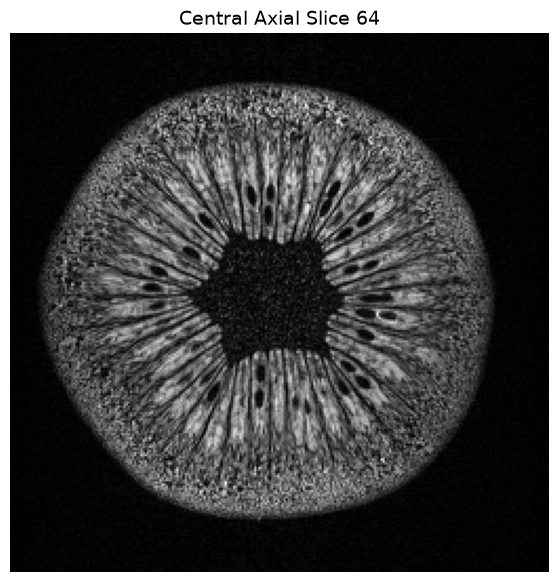

In [7]:
# Extract 2D axial slices along axis 2
slices = [data[:, :, z] for z in range(data.shape[2])]
print("Number of 2D axial slices:", len(slices))

sl = 64
fig, ax = plt.subplots(1, 1, figsize=(7, 7))
ax.imshow(slices[sl].T, cmap="gray", origin="lower")
ax.set_title(f"Central Axial Slice {sl}", fontsize=14)
ax.axis("off")
plt.show()

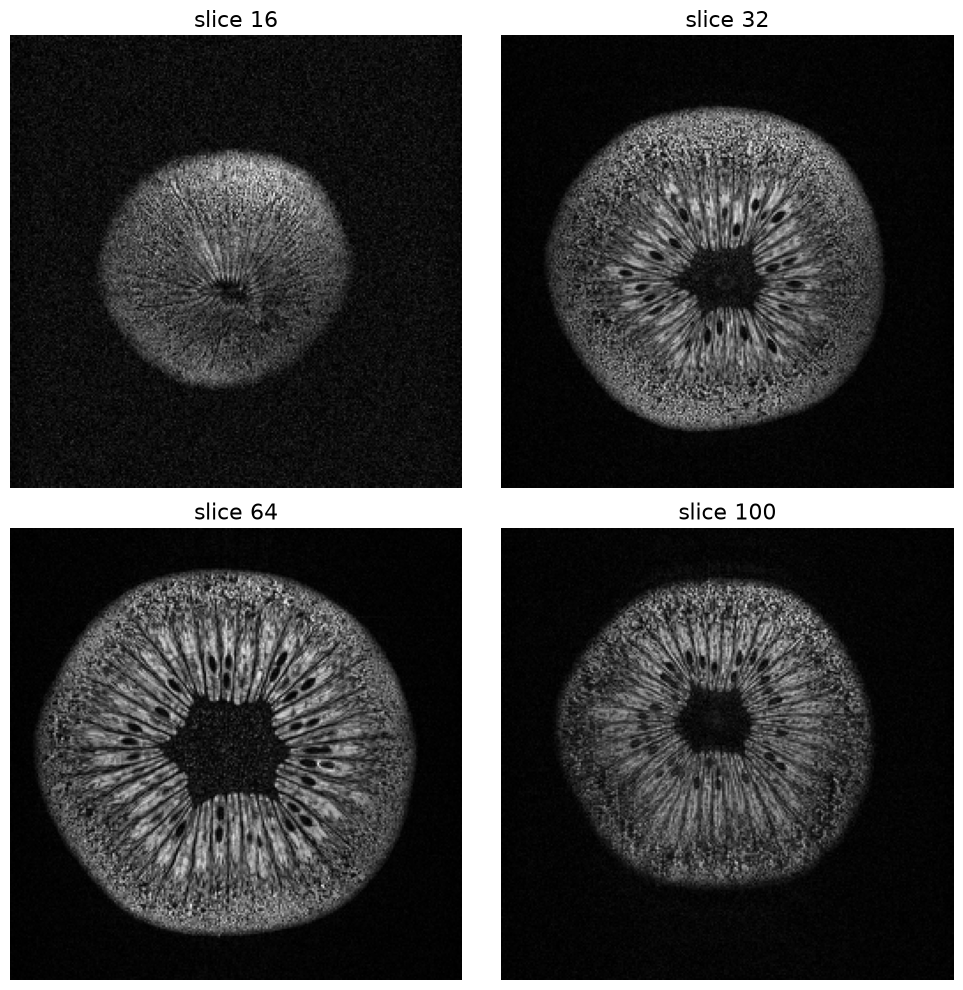

In [8]:
s = [16, 32, 64, 100]
fig = plt.figure("Selected axial slices", figsize=[10, 10])
for idx, sl_idx in enumerate(s, start=1):
    plt.subplot(2, 2, idx).set_axis_off()
    plt.title(f"slice {sl_idx}", fontsize=16)
    plt.imshow(data[:, :, sl_idx].T, cmap="gray", origin="lower")
plt.tight_layout()
plt.show()

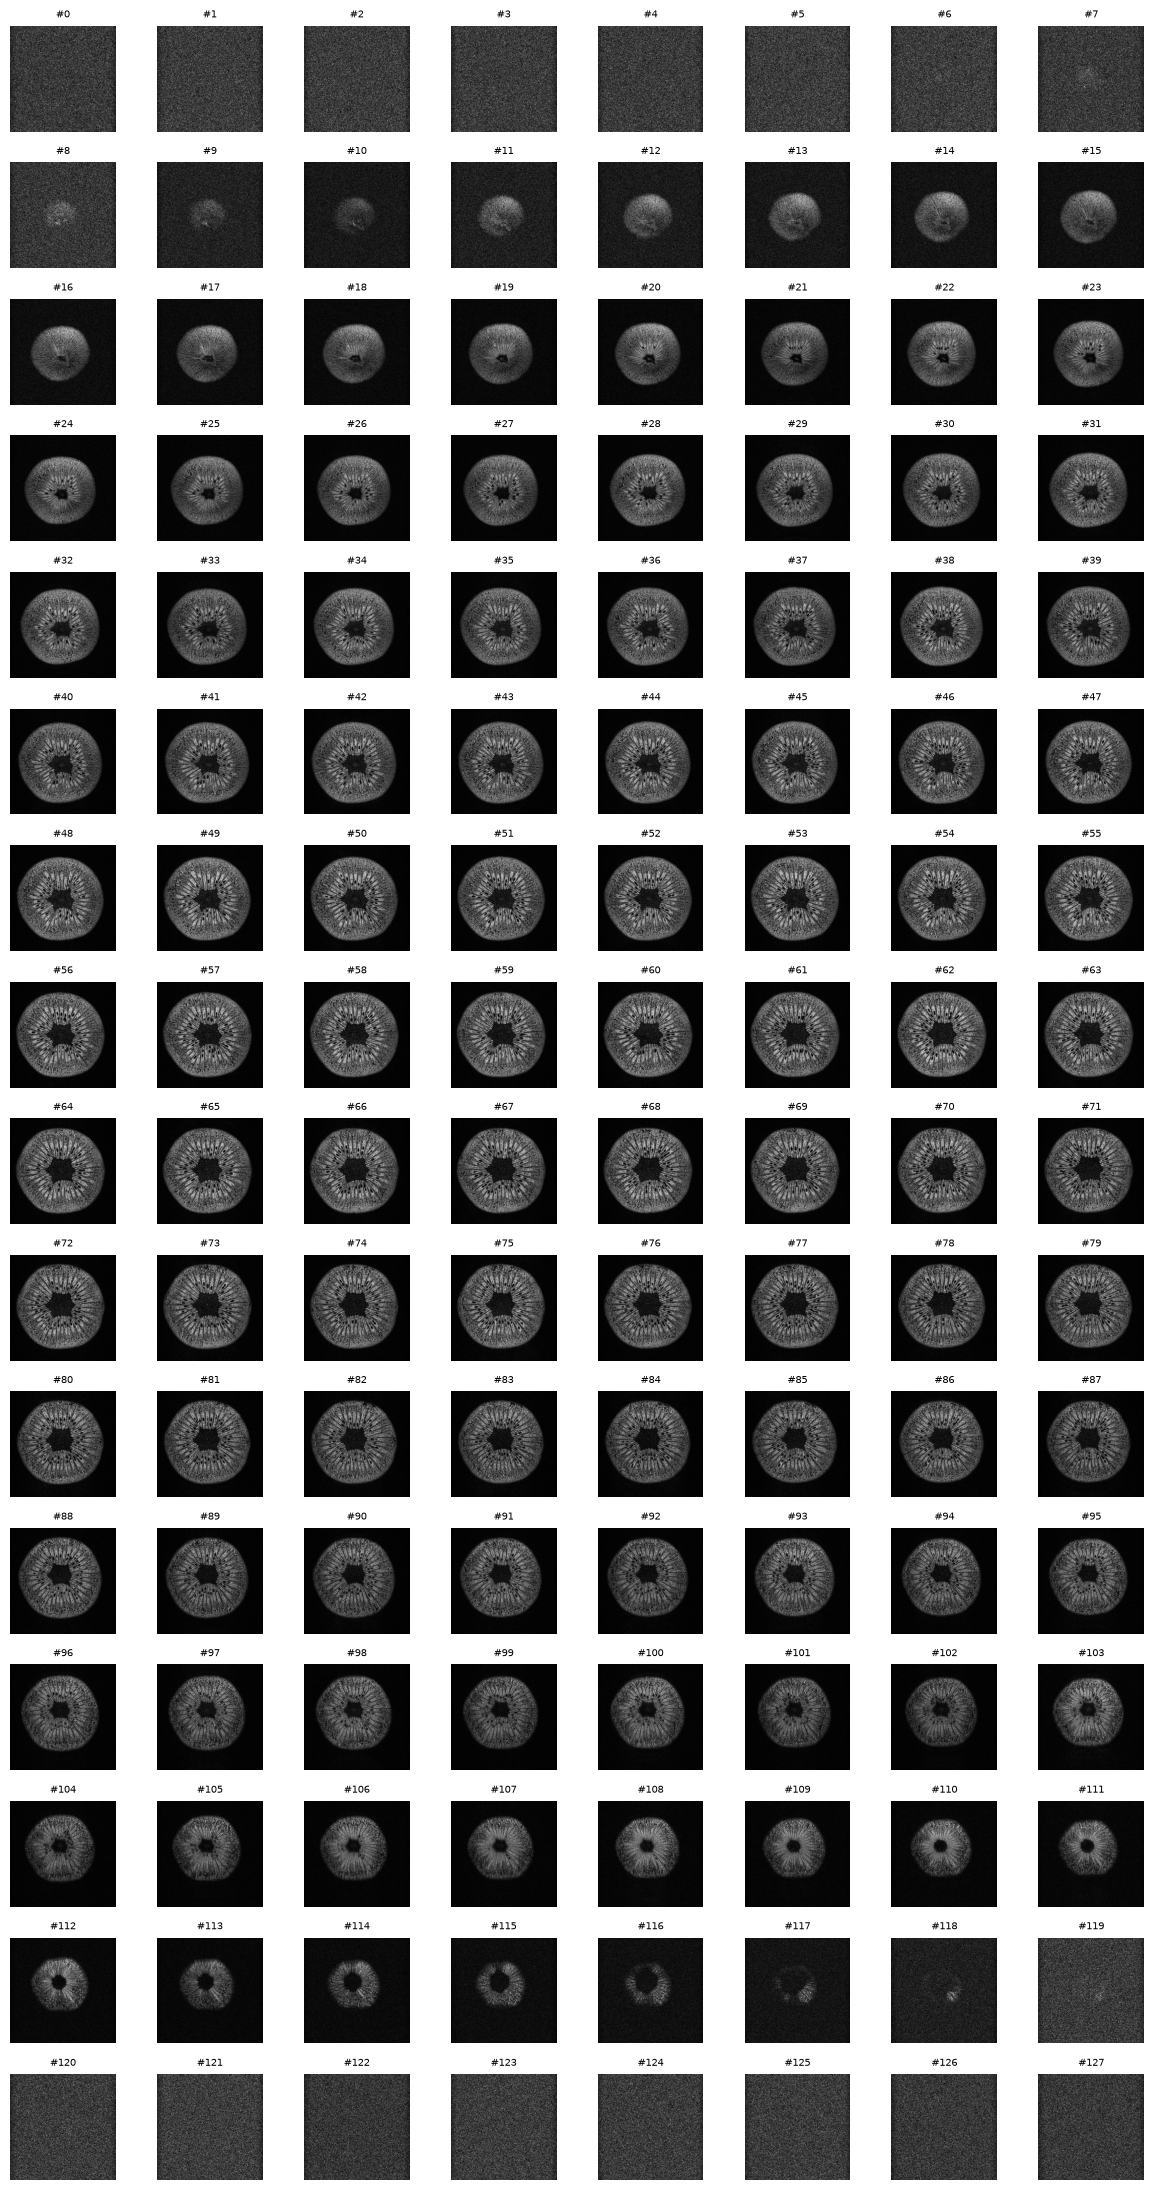

In [9]:
# Montage of all 128 transaxial slices
fig, axes = plt.subplots(16, 8, figsize=(12, 22))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(slices[i].T, cmap="gray", origin="lower")
    ax.set_title(f"#{i}", fontsize=7)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Saving Central Slice (`sl=64`) to PNG: Quantitative 16-bit vs. Display 8-bit

A classic pitfall in medical image processing is accidentally destroying **16-bit quantitative MRI intensities** (`[0 .. 32,766]`) when saving intermediate PNG files! Compare what happens with **Pillow (`PIL`)** versus **`matplotlib.image.imsave`** (using a temporary scratch file so we never overwrite git-tracked files in `../data/`):

In [10]:
def data_matrix_info(M):
    print("  shape =", M.shape, "| dtype =", M.dtype)
    print("  min = %.4f | max = %.4f | mean = %.4f | std = %.4f" % (M.min(), M.max(), M.mean(), M.std()))

scratch_png = pathlib.Path(tempfile.gettempdir()) / f"kiwi_{sl:03d}_scratch.png"
A = slices[sl]
print("Original 2D slice array A:")
data_matrix_info(A)

Original 2D slice array A:
  shape = (256, 256) | dtype = float64
  min = 71.0000 | max = 32766.0000 | mean = 5973.3852 | std = 6547.6558


**1. Pillow (`PIL` with `uint16`):** Preserves the exact 16-bit quantitative MRI signal intensities:

In [11]:
im_pil = PilImage.fromarray(A.astype(np.uint16))
im_pil.save(scratch_png)

A_PIL = np.array(PilImage.open(scratch_png))
print("Reloaded via Pillow (uint16):")
data_matrix_info(A_PIL)

Reloaded via Pillow (uint16):
  shape = (256, 256) | dtype = uint16
  min = 71.0000 | max = 32766.0000 | mean = 5973.3852 | std = 6547.6558


**2. `matplotlib.image.imsave`:** Maps intensities through a colormap into an 8-bit 4-channel RGBA `[0..1]` display image — losing the raw MRI scale!

In [12]:
import matplotlib.image
matplotlib.image.imsave(scratch_png, A)
A_matplotlib = matplotlib.image.imread(scratch_png)
print("Reloaded after matplotlib.image.imsave (colormapped RGBA!):")
data_matrix_info(A_matplotlib)

Reloaded after matplotlib.image.imsave (colormapped RGBA!):
  shape = (256, 256, 4) | dtype = float32
  min = 0.0039 | max = 1.0000 | mean = 0.4730 | std = 0.3400


**Conclusion:** Always keep quantitative MRI arrays in NIfTI/NumPy or 16-bit `PIL` (`uint16`), never colormapped display PNGs:

In [13]:
# Restore clean 16-bit grayscale slice for 2D segmentation experiments below
PilImage.fromarray(A.astype(np.uint16)).save(scratch_png)
slice_img = np.array(PilImage.open(scratch_png))
print("skimage version:", skimage.__version__)
data_matrix_info(slice_img)

skimage version: 0.26.0
  shape = (256, 256) | dtype = uint16
  min = 71.0000 | max = 32766.0000 | mean = 5973.3852 | std = 6547.6558


---

## Segmenting a Single Central Slice (`sl=64`)

*Image segmentation* partitions a digital image into meaningful regions (sets of pixels or voxels) [[Wikipedia](https://en.wikipedia.org/wiki/Image_segmentation)]. Starting on a single central slice (`sl=64`) is a natural way to build intuition before tackling the full 3D volume using [scikit-image](https://scikit-image.org/docs/stable/user_guide/tutorial_segmentation.html).

### Thresholding & Morphological Attribute Filtering

Thresholding algorithms in `scikit-image` fall into two broad categories:
- **Global histogram-based** (e.g. [Otsu's method](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.threshold_otsu)), which pick a single threshold for the entire slice.
- **Local / adaptive** (e.g. [`threshold_local`](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.threshold_local)) and **morphological [attribute operators](https://scikit-image.org/docs/stable/auto_examples/filters/plot_attribute_operators.html)** (`diameter_closing` / black top-hat), which compare each pixel against its local neighborhood.

> *Tip:* You can also preview many global thresholds at once with `from skimage.filters import try_all_threshold; fig, ax = try_all_threshold(slice_img, figsize=(10, 8), verbose=False)`.

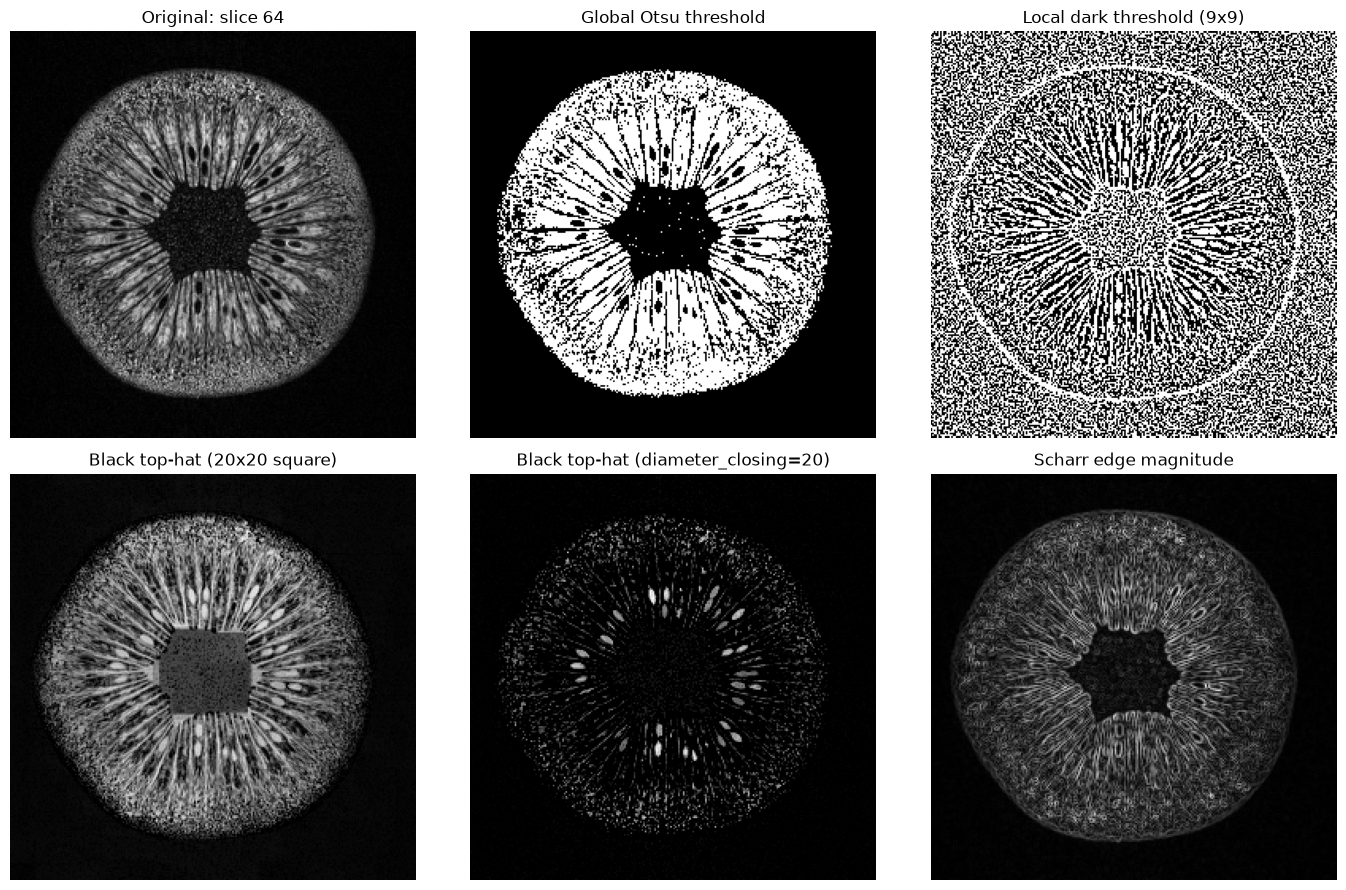

In [14]:
from skimage.filters import threshold_otsu, threshold_local, scharr
from skimage.morphology import closing, footprint_rectangle, diameter_closing

global_thresh = threshold_otsu(slice_img)
binary_global = slice_img > global_thresh

block_size = 9
local_thresh_map = threshold_local(slice_img, block_size, offset=10)
binary_local = slice_img < local_thresh_map  # True where pixel is darker than its 9x9 neighborhood

# Diameter closing removes dark structures whose maximal extension is smaller than `diameter` pixels.
# Subtracting the original slice highlights narrow dark pockets (black top-hat by diameter!).
diameter = 20
closed_attr = diameter_closing(slice_img, diameter, connectivity=2)
tophat_attr = closed_attr - slice_img

# Compare with standard morphological closing using a square structuring element
closed_rect = closing(slice_img, footprint_rectangle((diameter, diameter)))
tophat_rect = closed_rect - slice_img

edges = scharr(slice_img)

fig, axes = plt.subplots(ncols=3, nrows=2, figsize=(14, 9))
ax = axes.ravel()
panels = [
    (slice_img, f"Original: slice {sl}"),
    (binary_global, "Global Otsu threshold"),
    (binary_local, "Local dark threshold (9x9)"),
    (tophat_rect, "Black top-hat (20x20 square)"),
    (tophat_attr, "Black top-hat (diameter_closing=20)"),
    (edges, "Scharr edge magnitude"),
]
for a, (im_panel, title) in zip(ax, panels):
    a.imshow(im_panel.T, cmap="gray", origin="lower")
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()

## What Next? Three Classic Ideas
1. **Multispectral K-means clustering:** Stack selected filtered images as "channels" per pixel and run unsupervised [K-means clustering](https://en.wikipedia.org/wiki/K-means_clustering).
2. **Sparse manual annotation + Deep Learning:** Label all seeds in a handful of slices using [ITK-SNAP](http://www.itksnap.org/) or [3D Slicer](https://www.slicer.org/) and train a 2D/3D U-Net.
3. **Radiomics / filter-bank features:** Derive multi-scale texture and blobness feature maps (e.g., [PyRadiomics](https://pyradiomics.readthedocs.io/) or 3D Laplacian-of-Gaussian filters) for voxel/instance classification.

---

## Multispectral K-Means Clustering on Slice 64

Let us form an $n \times p$ feature matrix `X` (`n = 65,536` pixels, `p = 3` channels: `[Original, Local_bg, Tophat_attr]`), standardize each channel to zero mean and unit variance so no single intensity scale dominates Euclidean distance, and cluster into `K = 3` groups:

In [15]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

chn_names = ["Original", "Local_thresh_map", "Tophat_attr"]
X_raw = np.column_stack([
    slice_img.ravel(),
    local_thresh_map.ravel(),
    tophat_attr.ravel(),
])
X = StandardScaler().fit_transform(X_raw)
print("Feature matrix X shape:", X.shape)

K = 3
kmeans_model = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_fit = kmeans_model.fit(X)
print("Cluster labels:", kmeans_fit.labels_)
print("First centroid in standardized p-dimensional feature space:\n", kmeans_fit.cluster_centers_[0, :])

Feature matrix X shape: (65536, 3)
Cluster labels: [0 0 0 ... 0 0 0]
First centroid in standardized p-dimensional feature space:
 [-0.75809943 -0.85317979 -0.26053073]


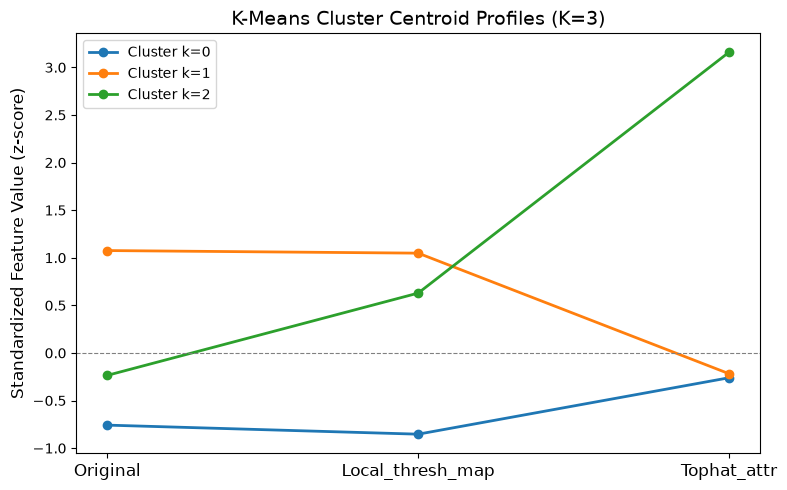

In [16]:
# Plot standardized cluster centroid profiles across the 3 feature channels
fig, ax = plt.subplots(figsize=(8, 5))
for k_idx in range(K):
    ax.plot(kmeans_fit.cluster_centers_[k_idx], "-o", linewidth=2, label=f"Cluster k={k_idx}")
ax.set_xticks(range(len(chn_names)))
ax.set_xticklabels(chn_names, fontsize=12)
ax.set_ylabel("Standardized Feature Value (z-score)", fontsize=12)
ax.set_title(f"K-Means Cluster Centroid Profiles (K={K})", fontsize=14)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.legend()
plt.tight_layout()
plt.show()

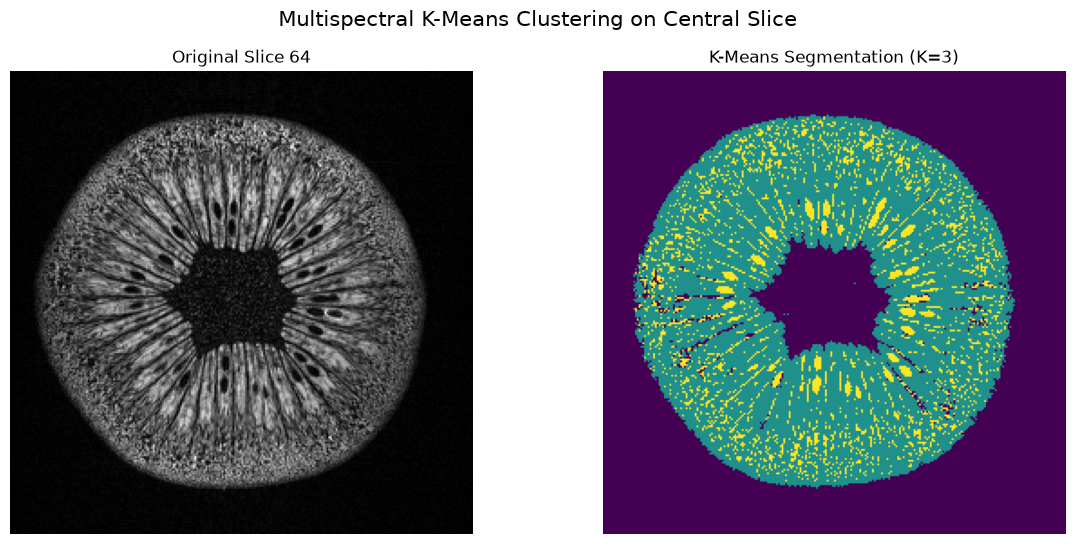

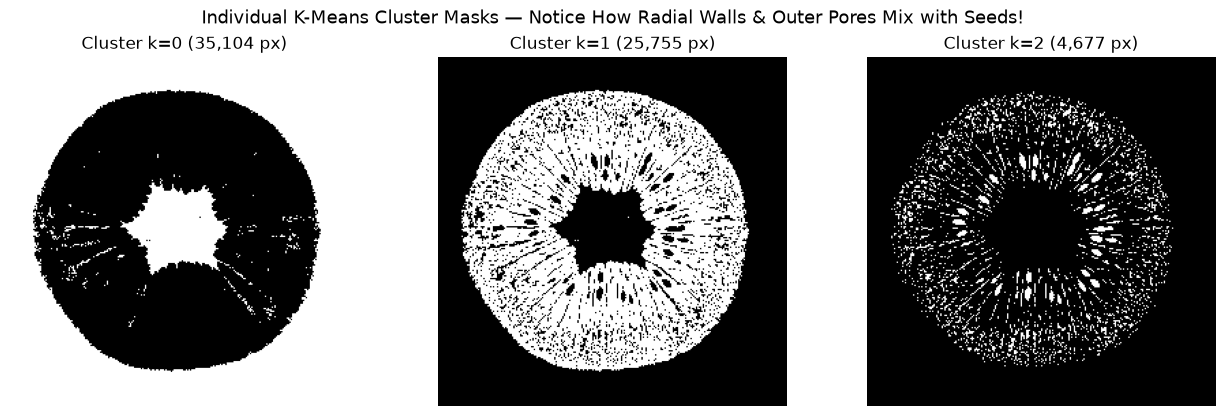

In [17]:
# Reshape flat cluster assignments back to 2D slice shape (equivalent to nested pixel loops, 100x faster)
kmeans_segm = kmeans_fit.labels_.reshape(slice_img.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
axes[0].imshow(slice_img.T, cmap="gray", origin="lower")
axes[0].set_title("Original Slice 64")
axes[0].axis("off")

axes[1].imshow(kmeans_segm.T, cmap="viridis", origin="lower")
axes[1].set_title(f"K-Means Segmentation (K={K})")
axes[1].axis("off")
plt.suptitle("Multispectral K-Means Clustering on Central Slice", fontsize=15)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, K, figsize=(13, 4.2))
for k_idx in range(K):
    clu = (kmeans_segm == k_idx).astype(float)
    axes[k_idx].imshow(clu.T, cmap="gray", origin="lower")
    axes[k_idx].set_title(f"Cluster k={k_idx} ({int(clu.sum()):,} px)")
    axes[k_idx].axis("off")
plt.suptitle("Individual K-Means Cluster Masks — Notice How Radial Walls & Outer Pores Mix with Seeds!", fontsize=13)
plt.tight_layout()
plt.show()

---

## Historical Milestone: Dagstuhl (2011) → 3D Variational Segmentation by Chan & Cai (2012)

The Kiwi Challenge has an international mathematical-imaging history stretching back more than fifteen years:

- **November 2011 (Schloss Dagstuhl, Germany):** Following discussions on mathematical imaging at a Dagstuhl Seminar, Arvid Lundervold shared this 7 T UiB kiwifruit MRI dataset with **Prof. Raymond H. Chan** (Department of Mathematics, The Chinese University of Hong Kong) as an open testbed for 3D segmentation.
- **February 2012 (CUHK, Hong Kong):** Prof. Chan invited his PhD student **Xiaohao Cai** to test their **variational two-stage convex Mumford–Shah segmentation method** on the 3D kiwi volume (cf. X. Cai, R. H. Chan, and T. Zeng, *"A Two-Stage Image Segmentation Method Using a Convex Variant of the Mumford–Shah Model and Thresholding"*, *SIAM Journal on Imaging Sciences*, 6(1):368–390, 2013).
- Below is Xiaohao Cai's February 2012 report figure (`kiwi_3d_01.pdf`), comparing **3D volume renderings** of the raw scan (Column 1) against **two 3D MATLAB `isosurface` seed segmentations** from four viewing angles (Columns 2 and 3):

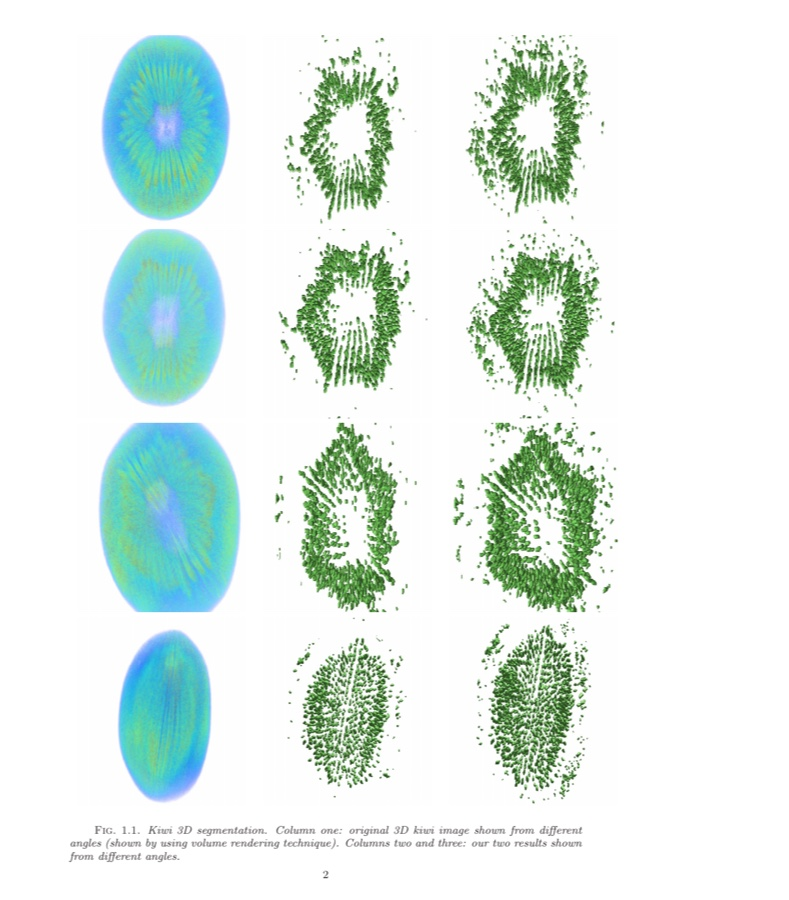

In [18]:
cai_fig_path = resolve_kiwi_file("assets/kiwi_3d_cai_chan_2012.jpg")
Image(filename=str(cai_fig_path), width=700)

### Prof. Raymond Chan's Question — And Why It Defines Notebook 03

When Prof. Raymond Chan sent Xiaohao Cai's 3D results back to Bergen on **27 February 2012**, his cover note asked a single, penetrating question:

> *"Attached is the segmentation result done by my student. **Could you give us comments as to the quality of the segmentation?**"*

Look closely at **Column 2** versus **Column 3** in Cai's figure above:
1. **Precision vs. Recall without Ground Truth:** Column 2 suppresses peripheral noise in the outer pericarp (*higher precision*), whereas Column 3 captures denser seed chains (*higher recall*), at the cost of extra outer specks. Without dissecting the fruit, **how do we prove objectively which setting is closer to biological truth?**
2. **Semantic Isosurfaces vs. 3D Instance Counting:** Even where the green 3D isosurface cleanly outlines the seed ring around the empty central core, tightly packed seeds along the same radial chamber merge into elongated tubes unless separated into **individual 3D seed instances**.

Answering Prof. Chan's question rigorously — moving from **2D single-slice exploration** to **3D anisotropic instance segmentation** and a **4-Panel Semi-Verifiability Dashboard** — is the exact mission of **[`03-kiwi-paradigms-and-verification.ipynb`](./03-kiwi-paradigms-and-verification.ipynb)**!

---

### Where to Go Next in the Kiwi Challenge Trilogy

- **Notebook 01 (`01-kiwi-explore.ipynb`):** 3D NIfTI/DICOM headers, physical voxel geometry & affine coordinate systems
- **Notebook 02 (`02-kiwi-seeds-explore.ipynb`):** 2D single-slice filtering, thresholding, unsupervised K-means & the 2011–2012 Dagstuhl / CUHK 3D variational segmentation milestone
- **Notebook 03 (`03-kiwi-paradigms-and-verification.ipynb`):** Full 3D segmentation ladder (Rung 1 → Rung 2B → Foundation Models & Agents), quantitative "lesion load", & the **4-Panel Semi-Verifiability Dashboard**